# Figure 2 — short test

Terrain behavior, ER controls, temporal sensitivity, blockade and neural gain planes.

The saved tables and figures below come from a real short test and can be viewed directly on GitHub. To regenerate them, use the **Python (FlyControl)** kernel; see [setup and notebook index](README.md). Run cells from top to bottom. This notebook executes the same six stages as the command-line workflow, with reduced budgets and one training seed. It keeps every configured method. **These are software checks, not paper results.**

First execution downloads versioned public inputs. Neural assays and multi-stage maze prerequisites can still take substantial time; “short” refers to the training budget, not a seconds-long demonstration. Generated checkpoints, data and figures stay under `runs/`.

Choose a fresh `RUN_DIR` after code/configuration changes or for an independent restart. A completed run can be inspected with the “Inspect the smoke outputs” cell without retraining.

## Settings

Launch Jupyter from the repository root or `notebooks/`. Select the installed FlyControl kernel before running.

`DEVICE` defaults to CPU. To use a GPU, set it to an available device (for example `cuda:0`) or launch Jupyter with `FLYCONTROL_NOTEBOOK_DEVICE=cuda:0`. The saved execution records the device actually used.

In [1]:
from pathlib import Path
import sys
import os

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src/flycontrol").is_dir()
)
sys.path.insert(0, str(ROOT / "notebooks"))
from notebook_utils import run_stage, show_outputs

CONFIG = 'terrain'
RUN_DIR = ROOT / "runs/notebooks" / CONFIG
DEVICE = os.environ.get("FLYCONTROL_NOTEBOOK_DEVICE", "cpu")
WORKERS = 1
print(f"SMOKE TEST: {CONFIG} | {DEVICE} | {RUN_DIR.relative_to(ROOT)}")


SMOKE TEST: terrain | cuda:0 | runs/notebooks/terrain


## 1. Prepare

Download and checksum-verify public inputs, then resolve the reduced configuration. This cell always sets `--smoke`; all configured methods and the first training seed are retained.

In [2]:
run_stage("prepare", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: prepare** · 40.9 seconds · smoke test

Full execution log: `logs/notebook-prepare.log` within the run directory.

## 2. Train

Train fresh policies using the reduced budgets. This includes any prerequisites required by the selected experiment.

In [3]:
run_stage("train", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: train** · 451.7 seconds · smoke test

Full execution log: `logs/notebook-train.log` within the run directory.

## 3. Evaluate

Run the configured smoke evaluations in the real simulator, recording failures as well as successful episodes.

In [4]:
run_stage("evaluate", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: evaluate** · 103.1 seconds · smoke test

Full execution log: `logs/notebook-evaluate.log` within the run directory.

## 4. Probe

Run the configured neural assays. Experiments without a neural assay record that explicitly. Short-trained policies can fail the required histories; read the recorded exclusions.

In [5]:
run_stage("probe", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: probe** · 80.3 seconds · smoke test

Full execution log: `logs/notebook-probe.log` within the run directory.

## 5. Analyze

Aggregate the generated numerical records. Smoke outputs do not support the manuscript’s statistical conclusions.

In [6]:
run_stage("analyze", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: analyze** · 1.2 seconds · smoke test

Full execution log: `logs/notebook-analyze.log` within the run directory.

## 6. Plot

Create diagnostic panels, numerical sources and editable PDF/SVG figures from this run.

In [7]:
run_stage("plot", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: plot** · 15.1 seconds · smoke test

Full execution log: `logs/notebook-plot.log` within the run directory.

## Inspect the smoke outputs

Check completion and effective settings, then inspect sample tables and up to three generated figures. All files remain available in `RUN_DIR`.

**SMOKE TEST — not paper results.**

,experiment,methods,training seeds
0,terrain,"connectome, mlp, er",[2011]


Source/configuration SHA-256: `eaab77b7c7f8b5c50e7015c4c1c15e9ce272e2e432760c88fcc2e24c7a48ea9f`

,stage,completed,elapsed seconds
0,prepare,True,40.87
1,train,True,451.73
2,evaluate,True,103.06
3,probe,True,80.27
4,analyze,True,1.17
5,plot,True,15.11


`analysis/seed_means.csv` (first eight rows)

...

`analysis/episodes.csv` (first eight rows)

,method,model,training_seed,height,phase_seed,mode,success,crossed_within_corridor,duration_s,completion_time_with_failure_horizon_s,...,actual_obstacle_near_x_mm,actual_obstacle_far_x_mm,minimum_ground_edge_margin_mm,body_state_not_translated,geometry_audit,obstacle_contact_macro_samples,trace_sha256,snapshot_replay_verified,seed,condition
0,connectome,Adult,2011,0.0,1903000020,steady_start_full,True,True,0.50,0.50,...,17.908257,19.208257,22.812836,True,"{'ray_distance': 1.0, 'ray_hit_geom': 0, 'obst...",0,bd2ab98ace2e1d5d2f72d2e14f34e39a7089d89ca80b24...,True,2011,0 mm
1,er,MLP,2011,0.0,1903000020,steady_start_full,True,True,0.51,0.51,...,17.908257,19.208257,22.812836,True,"{'ray_distance': 1.0, 'ray_hit_geom': 0, 'obst...",0,3b0b45495f6d1fc2ef6af730738d7f41593f8c44d1ef5b...,True,2011,0 mm
2,mlp,MLP,2011,0.0,1903000020,steady_start_full,True,True,0.51,0.51,...,17.908257,19.208257,22.812836,True,"{'ray_distance': 1.0, 'ray_hit_geom': 0, 'obst...",0,6da87d95f9ab47f6bec56afed1d758f8e8ea8b57fe3786...,True,2011,0 mm


`analysis/observed_counts.csv` (first eight rows)

,method,seed,condition,success,crossed_within_corridor,residual_variation_per_observed_second,max_lateral_mm
0,connectome,2011,0 mm,1,1,1,1
1,er,2011,0 mm,1,1,1,1
2,mlp,2011,0 mm,1,1,1,1


`figures/paper/F2_anatomical_atlas.png`

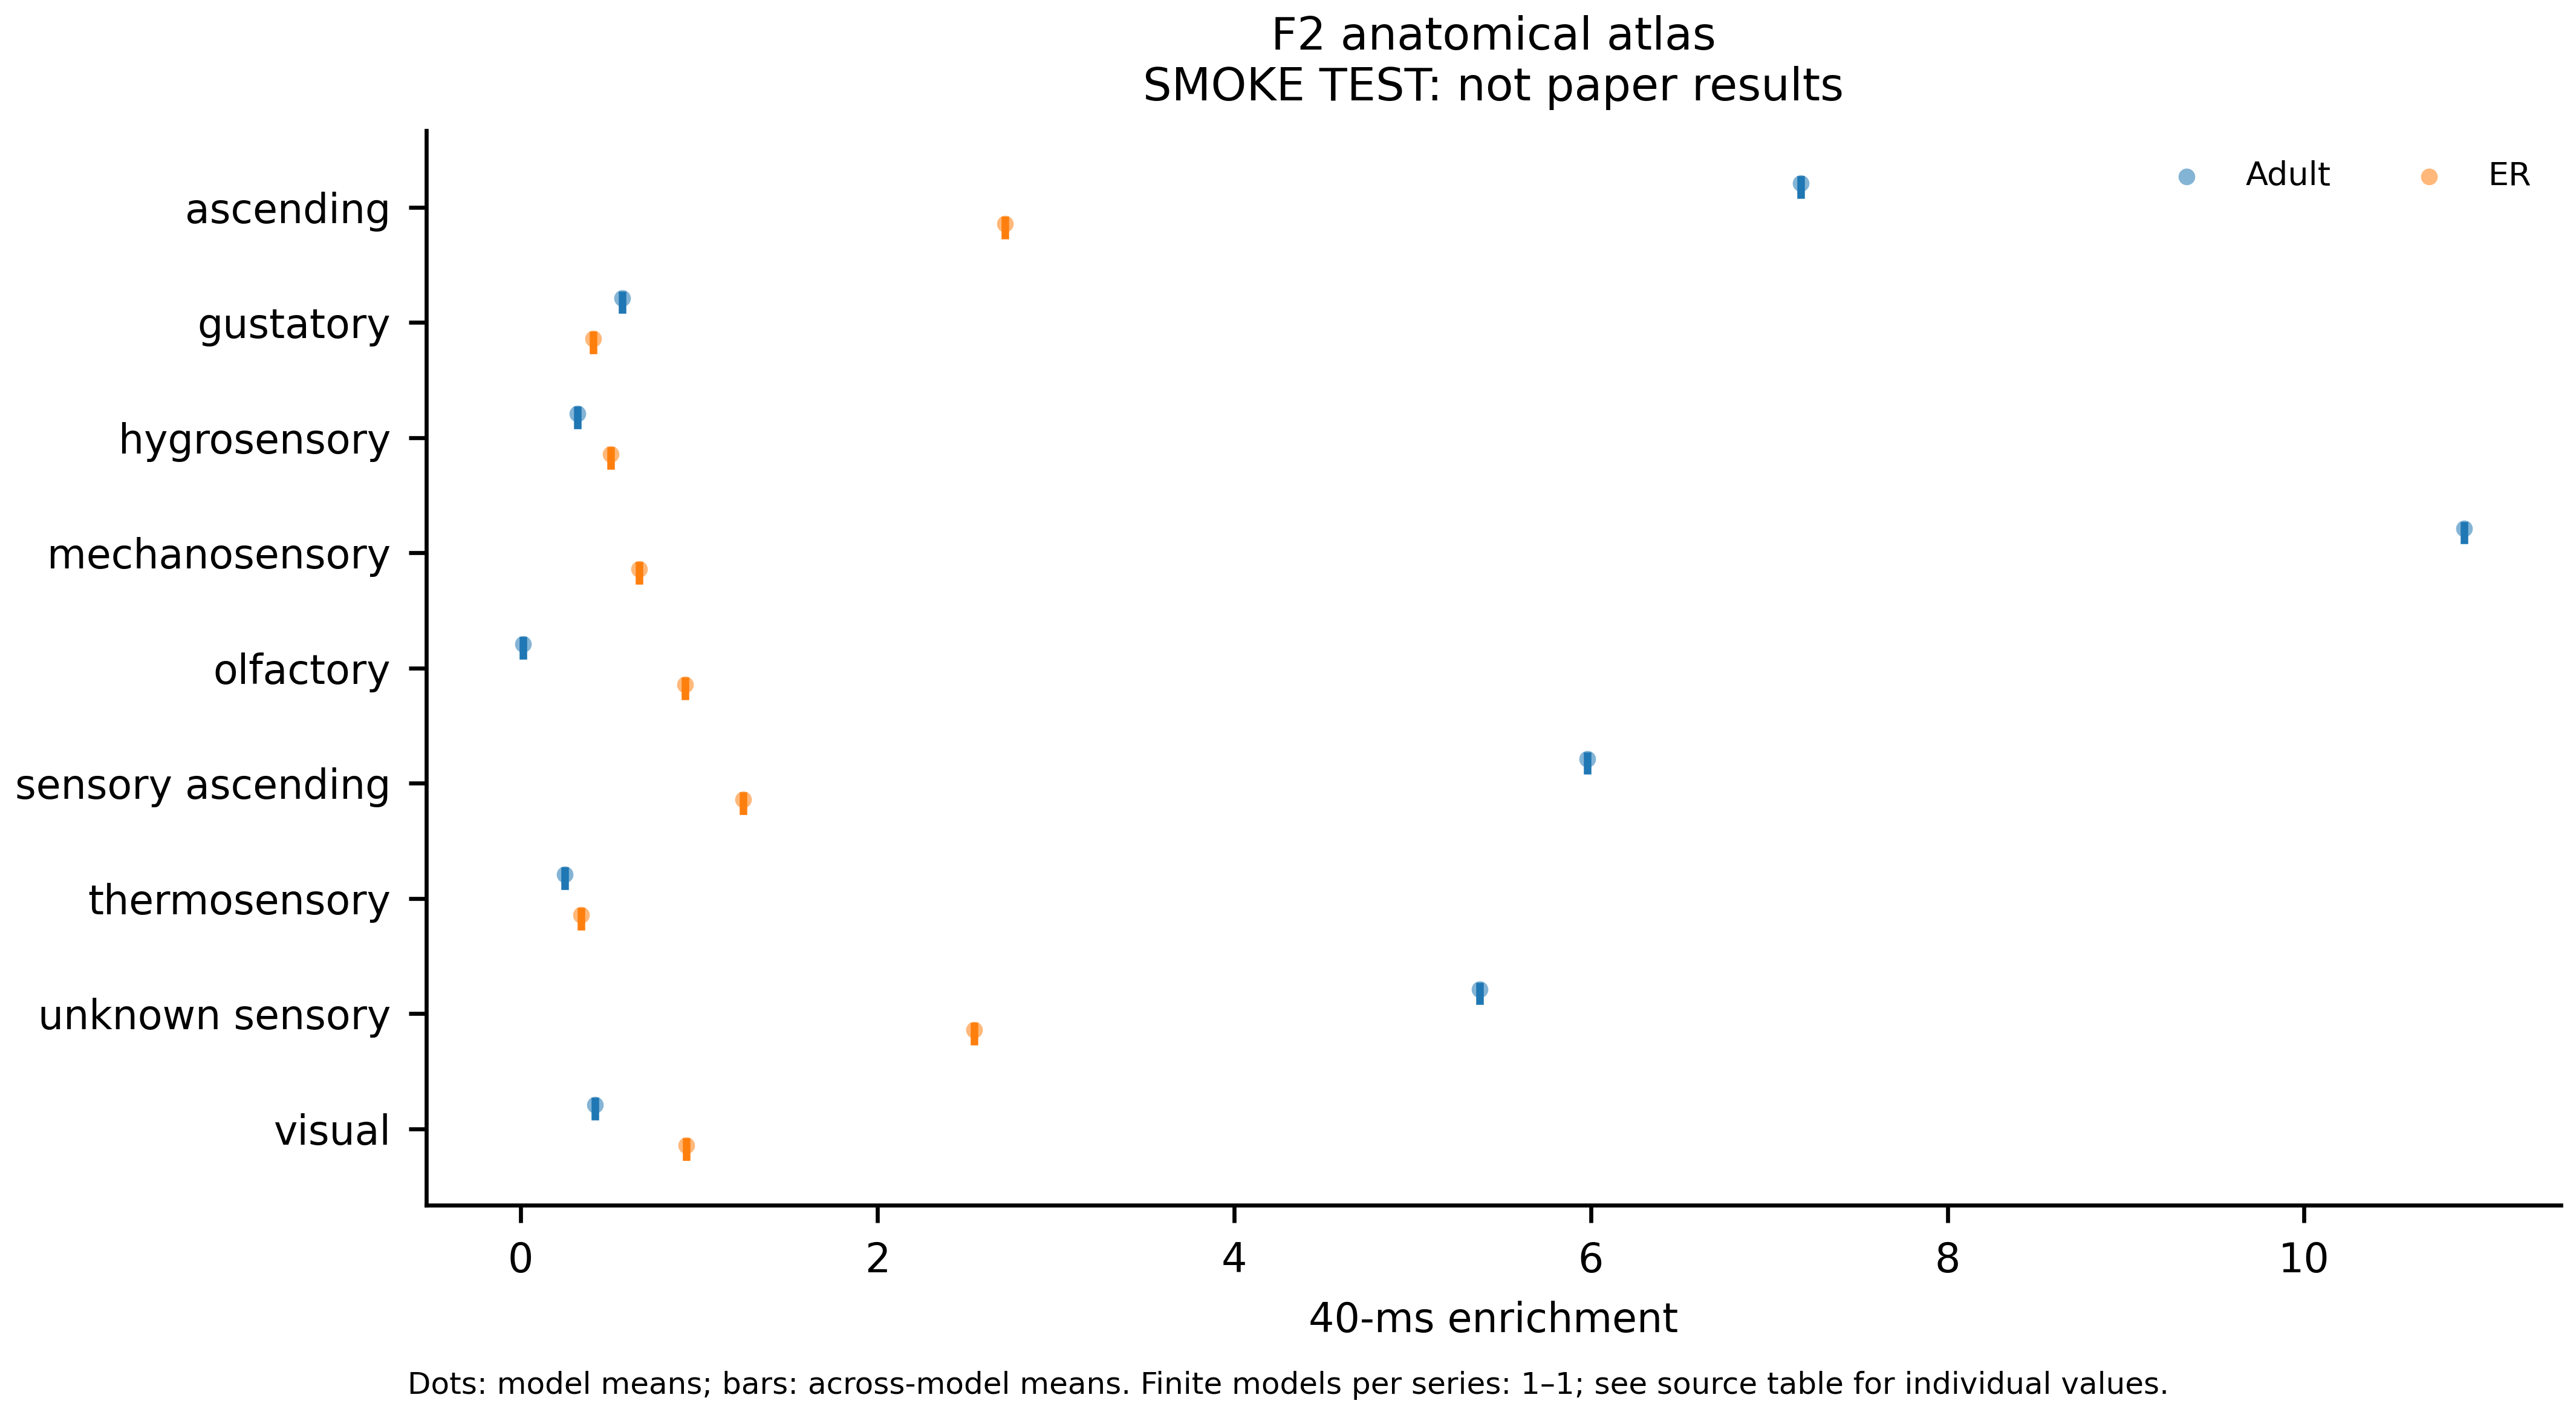

`figures/paper/F2_reversible_interventions.png`

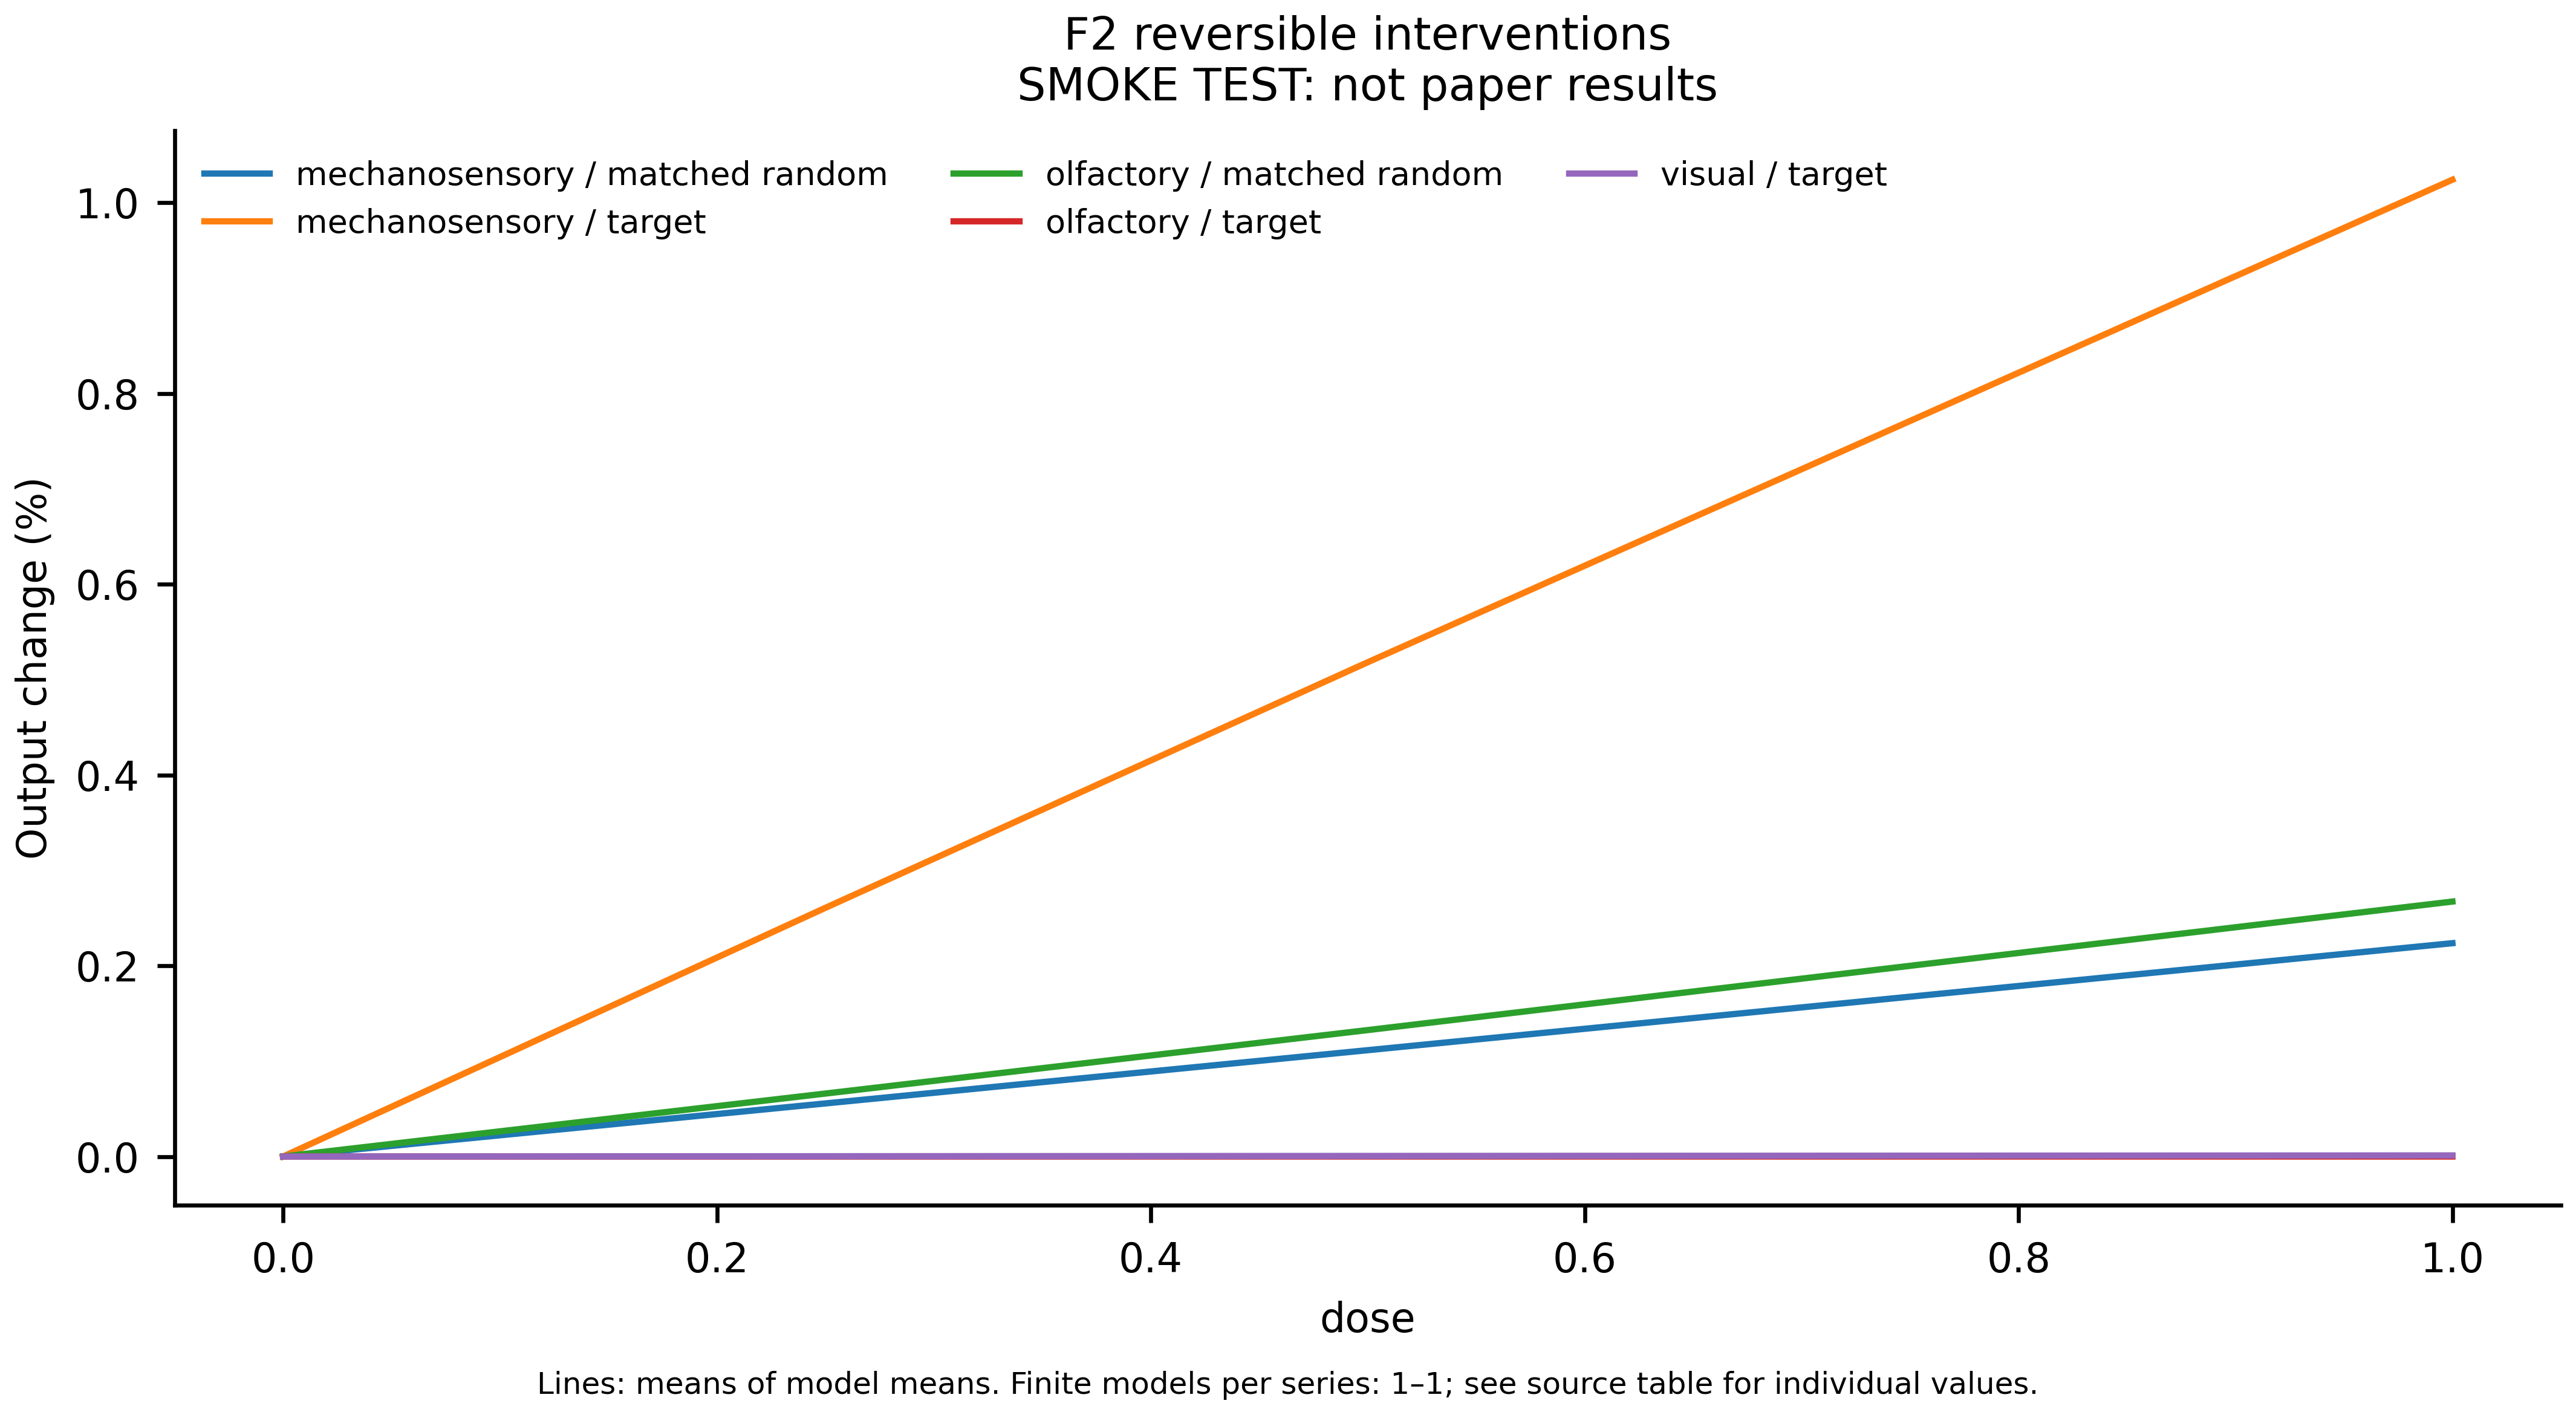

`figures/paper/F2_temporal_sensitivity.png`

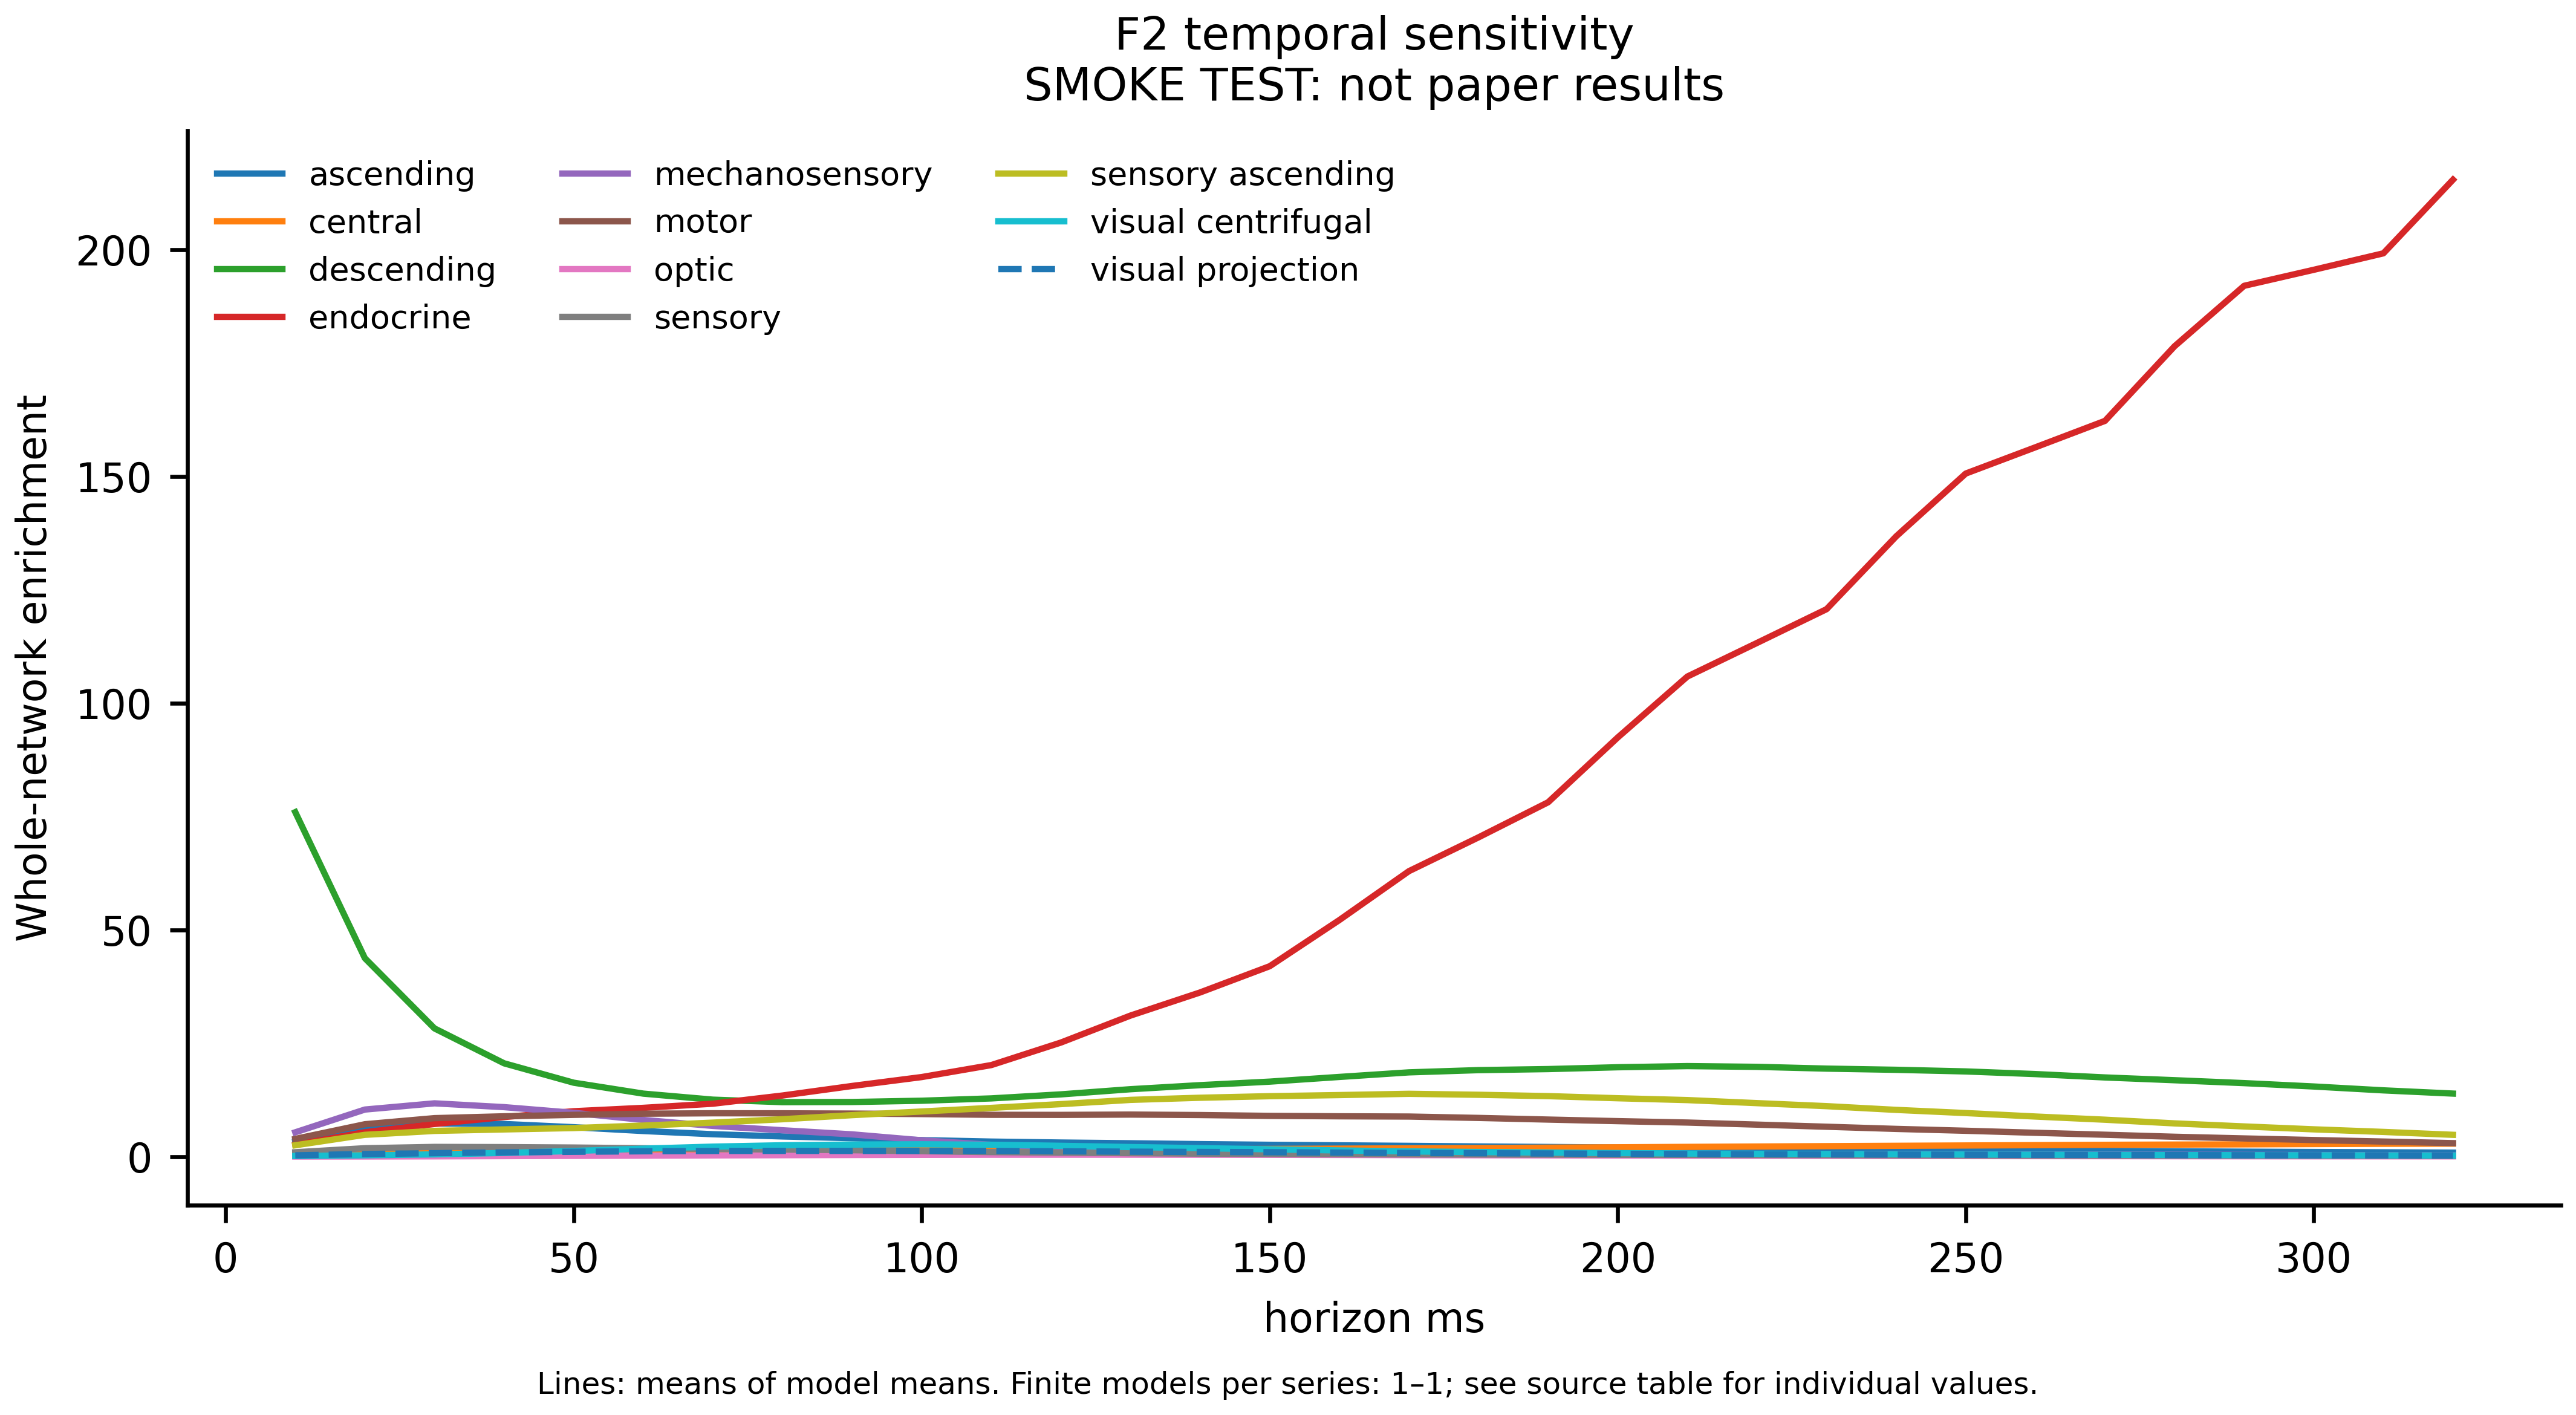

The complete numerical files and figures are saved in `RUN_DIR`. The tables and images displayed here are embedded in this notebook.

In [8]:
show_outputs(RUN_DIR)

## Full reproduction

Run this command in a terminal from the repository root, with the environment activated:

```bash
python scripts/02_terrain.py --run-dir runs/terrain --device cuda:0 --workers 4
```

Equivalent command:

```bash
flycontrol run --config terrain --run-dir runs/terrain --device cuda:0 --workers 4
```

Use an available CUDA device, or `cpu`. Without `--smoke`, the script uses the complete fixed seed cohort, training budgets and condition grids. Keep full outputs in a separate run directory. These commands are documentation only; **Run All never launches the full campaign**.
